# **Vertente explorada: Relação Cliente x Serviços**

In [77]:
# Importando bibliotecas

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t

# Instale antes se necessário: pip install tabulate
from tabulate import tabulate

## **Variáveis segmentadas por tema**

- *Cliente*

    - ID_Cliente: ID de identificação do cliente;

    - Genero: Gênero do cliente (Masculino / Feminino);

    - Idoso: Indica se o cliente é idoso;

    - Conjuge: Indica se o cliente possui cônjuge/parceiro;

    - Dependentes: Indica se o cliente possui dependentes.

- *Serviços*

    - Servico_Telefonia: Indica se o cliente possui assinatura de serviço telefônico;

    - Varias_Linhas: Indica se o cliente possui múltiplas linhas telefônicas;

    - Servico_Internet: Tipo de provedor de internet contratado (DSL, Fibra óptica ou Sem serviço);

    - Seguranca_Online: Indica se possui serviço adicional de segurança online;

    - Backup_Online: Indica se possui serviço adicional de backup na nuvem;

    - Protecao_Dispositivos: Indica se possui seguro/proteção para os aparelhos;

    - Suporte_Tecnico: Indica se possui plano de suporte técnico dedicado;

    - Streaming_TV: Indica se utiliza o serviço de streaming de TV;

    - Streaming_Filmes: Indica se utiliza o serviço de streaming de filmes.

## **Perguntas de Orientação**

In [78]:
df_silver = pd.read_csv("tabela_silver.csv")

- Criamos uma cópia para alterações

In [79]:
df = df_silver.copy()

### **Qual é o perfil geral de contratação dos serviços na base?**

Objetivo: Entender quais são os serviços mais populares e quais têm menor adesão.

In [80]:
# Ver o número de Telefonia

tel_df = pd.DataFrame({
    'Quantidade': df['Servico_Telefonia'].value_counts(),
    'Percentual (%)': round(df['Servico_Telefonia'].value_counts(normalize=True) * 100, 2)
})
print("--- Telefonia ---")
display(tel_df)

--- Telefonia ---


,Quantidade,Percentual (%)
Servico_Telefonia,,
True,5071,90.01
False,563,9.99


In [81]:
# Ver o número de Internet

net_df = pd.DataFrame({
    'Quantidade': df['Servico_Internet'].value_counts(),
    'Percentual (%)': round(df['Servico_Internet'].value_counts(normalize=True) * 100, 2)
})
print("\n--- Internet ---")
display(net_df)


--- Internet ---


,Quantidade,Percentual (%)
Servico_Internet,,
Fibra óptica,2477,43.97
DSL,1924,34.15
Sem serviço de internet,1233,21.88


In [82]:
# Serviços adicionais

# Criando a lista de colunas
servicos = ['Varias_Linhas', 'Seguranca_Online', 'Backup_Online', 
            'Protecao_Dispositivos', 'Suporte_Tecnico', 'Streaming_TV', 'Streaming_Filmes']

# Criar um dicionário vazio
resumo = {}

for col in servicos:
    quantidade = (df[col] == "Sim").sum()
    porcentagem = (quantidade / len(df)) * 100
    resumo[col] = {"Quantidade": quantidade, "Percentual (%)": round(porcentagem, 2)}
    

# Transformando em uma tabela e ordenando. T (transposição). Ordena a tabela da maior qtd para a menor sort_values(by='Quantidade', ascending=False)

df_resumo = pd.DataFrame(resumo).T.sort_values(by='Quantidade', ascending=False)


print("\n--- Serviços Adicionais ---")
display(df_resumo)




--- Serviços Adicionais ---


,Quantidade,Percentual (%)
Varias_Linhas,2367.0,42.01
Streaming_TV,2182.0,38.73
Streaming_Filmes,2177.0,38.64
Backup_Online,1944.0,34.50
Protecao_Dispositivos,1932.0,34.29
Suporte_Tecnico,1610.0,28.58
Seguranca_Online,1598.0,28.36


C:\Users\Ana_Lucia\AppData\Local\Temp\ipykernel_27244\1029239965.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Servico_Internet', order=order_net, palette='viridis')


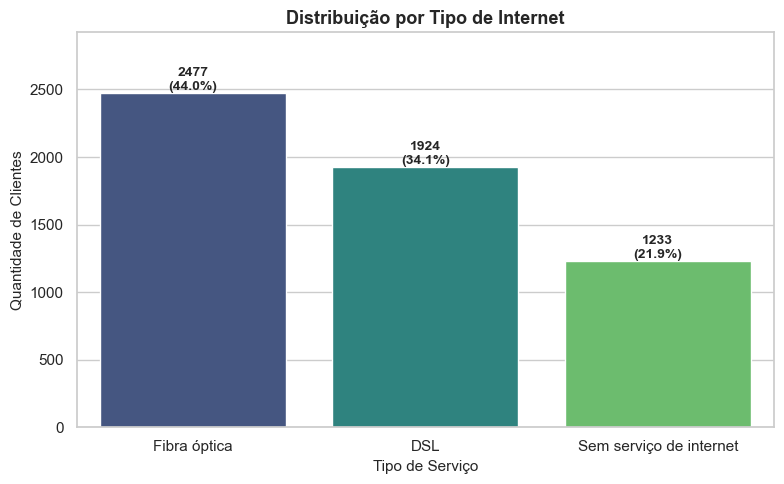

In [83]:
# Configurar o estilo visual do gráfico com fundo quadriculado limpo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Definir a ordem que as barras vão aparecer no eixo X
order_net = ['Fibra óptica', 'DSL', 'Sem serviço de internet']

# Criar o gráfico de barras usando o Seaborn
ax = sns.countplot(data=df, x='Servico_Internet', order=order_net, palette='viridis')

# Adicionar o título e os nomes dos eixos
plt.title('Distribuição por Tipo de Internet', fontsize=13, fontweight='bold')
plt.xlabel('Tipo de Serviço', fontsize=11)
plt.ylabel('Quantidade de Clientes', fontsize=11)

# Laço para calcular e escrever os números e porcentagens em cima de cada barra
total_clientes = len(df)
for p in ax.patches:
    val = int(p.get_height())
    pct = (val / total_clientes) * 100
    ax.annotate(f'{val}\n({pct:.1f}%)', 
                (p.get_x() + p.get_width() / 2., val),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Aumentar um pouco o limite do eixo Y para dar espaço aos números no topo
plt.ylim(0, df['Servico_Internet'].value_counts().max() * 1.18)

# rganizar o layout e exibir o gráfico
plt.tight_layout()
plt.show()

Gráfico: Serviços adicionais

C:\Users\Ana_Lucia\AppData\Local\Temp\ipykernel_27244\2026531912.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_grafico, x='Percentual', y='Servico', palette='magma')


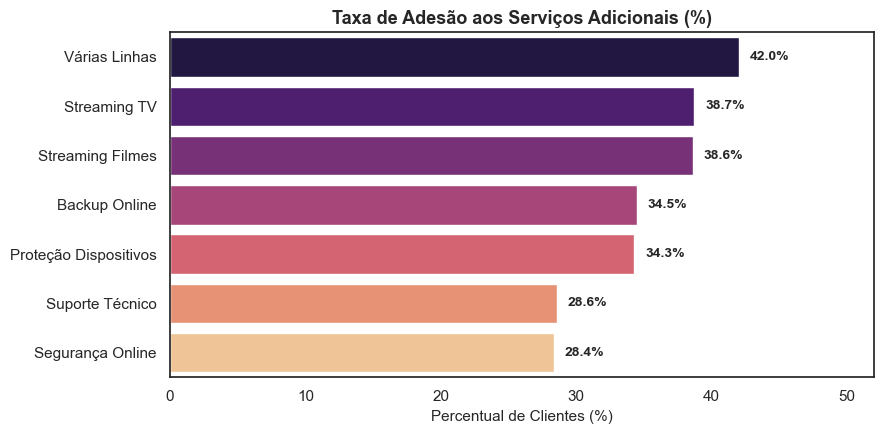

In [84]:

# Calcular a porcentagem de 'Sim' para cada serviço adicional
servicos = [
    'Varias_Linhas',
    'Seguranca_Online',
    'Backup_Online',
    'Protecao_Dispositivos',
    'Suporte_Tecnico',
    'Streaming_TV',
    'Streaming_Filmes',
]

sim_pct = {}
for col in servicos:
  qtd_sim = (df[col] == 'Sim').sum()
  pct = (qtd_sim / len(df)) * 100
  sim_pct[col] = pct

# Transformar em DataFrame e ordenar do MAIOR para o MENOR
df_grafico = pd.DataFrame(list(sim_pct.items()), columns=['Servico', 'Percentual']).sort_values(
    by='Percentual', ascending=False
)

# Renomear os nomes dos serviços para nomes mais amigáveis
labels_map = {
    'Varias_Linhas': 'Várias Linhas',
    'Streaming_Filmes': 'Streaming Filmes',
    'Streaming_TV': 'Streaming TV',
    'Backup_Online': 'Backup Online',
    'Protecao_Dispositivos': 'Proteção Dispositivos',
    'Suporte_Tecnico': 'Suporte Técnico',
    'Seguranca_Online': 'Segurança Online',
}
df_grafico['Servico'] = df_grafico['Servico'].map(labels_map)

# Configurar e desenhar o gráfico
sns.set_theme(style='white')  # <- Mudado de 'whitegrid' para 'white' (fundo totalmente limpo)
plt.figure(figsize=(9, 4.5))

ax = sns.barplot(data=df_grafico, x='Percentual', y='Servico', palette='magma')

plt.title('Taxa de Adesão aos Serviços Adicionais (%)', fontsize=13, fontweight='bold')
plt.xlabel('Percentual de Clientes (%)', fontsize=11)
plt.ylabel('')

# O comando abaixo garante que nenhuma linha de grade apareça no fundo
plt.grid(False)

# 5. Laço para escrever a porcentagem exata ao lado de cada barra
for p in ax.patches:
  w = p.get_width()
  ax.annotate(
      f'{w:.1f}%',
      (w + 0.8, p.get_y() + p.get_height() / 2.0),
      ha='left',
      va='center',
      fontsize=10,
      fontweight='bold',
  )

# Ajustar o limite do eixo X para dar espaço aos números
plt.xlim(0, 52)
plt.tight_layout()
plt.show()

### 📝 Conclusão - Perfil Geral de Contratação dos Serviços

Com base na análise exploratória da base de dados, podemos destacar os principais comportamentos de contratação dos clientes:

1. **Serviço de Telefonia (Base Fervorosa):**
   * A telefonia atua como o principal produto âncora da empresa, sendo contratada por expressivos **90,01%** dos clientes (5.071 usuários), contra apenas 9,99% que não possuem o serviço.

2. **Preferência Tecnológica em Internet:**
   * Entre os serviços de internet, a **Fibra óptica** lidera com **43,97%** da base total (2.477 clientes), superando a tecnologia **DSL** (**34,15%** / 1.924 clientes). 
   * Cerca de **21,88%** dos clientes optam por não contratar internet, ficando apenas com os serviços de telefonia básica.

3. **Adesão aos Serviços Adicionais (Valor Agregado):**
   * **Destaques de Popularidade:** O serviço adicional mais contratado é o de **Várias Linhas**, alcançando **42,01%** de adesão, seguido de perto pelas plataformas de entretenimento como **Streaming de TV** (**38,73%**) e **Streaming de Filmes** (**38,64%**).
   * **Oportunidades de Crescimento:** Os serviços voltados à segurança e assistência técnica (**Suporte Técnico** com 28,58% e **Segurança Online** com 28,36%) apresentam as menores taxas de penetração, indicando um excelente espaço para campanhas de vendas cruzadas (*cross-sell*).

__________________________________________________________________________________________________________________________________________

### **Clientes idosos (Idoso) têm preferência por algum tipo de internet ou contratam mais suporte técnico (Suporte_Tecnico)?**

In [85]:
# Cruzamento de Idoso x Tipo de INternet (%)

print("--- Preferência de Internet por Idosos (%) ---")
internet_idoso = (
    pd.crosstab(df['Idoso'], df['Servico_Internet'], normalize='index') * 100
).round(2)
display(internet_idoso)


# Cruzamento de Idoso x Suporte Técnico (%)
print("\n--- Contratação de Suporte Técnico por Idosos (%) ---")
suporte_idoso = (
    pd.crosstab(df['Idoso'], df['Suporte_Tecnico'], normalize='index') * 100
).round(2)
display(suporte_idoso)

--- Preferência de Internet por Idosos (%) ---


Servico_Internet,DSL,Fibra óptica,Sem serviço de internet
Idoso,,,
False,36.36,38.31,25.33
True,22.95,72.63,4.42



--- Contratação de Suporte Técnico por Idosos (%) ---


Suporte_Tecnico,Não,Sem serviço de internet,Sim
Idoso,,,
False,44.90,25.33,29.77
True,73.06,4.42,22.52


📊 O que os dados revelam:

    Sobre o Tipo de Internet (Servico_Internet):

Sim, existe uma preferência muito forte! Os clientes idosos dão absoluta preferência à Fibra óptica, que é contratada por 72,6% deles (674 clientes).

Em contrapartida, apenas 23,0% usam internet DSL e meros 4,4% ficam sem serviço de internet. Entre os não idosos, o uso da Fibra óptica é bem menor (38,3%).

    Sobre o Suporte Técnico (Suporte_Tecnico):

Surpreendentemente, NÃO. Apesar de usarem a internet mais avançada, a grandíssima maioria dos idosos (73,1%) não contrata o serviço de suporte técnico.

Apenas 22,5% possuem o suporte técnico contratado (e 4,4% não têm internet). Isso mostra um ponto crítico de atenção para a empresa: o público idoso é o que mais usa fibra óptica, mas é o que menos protege o plano com assistência técnica.

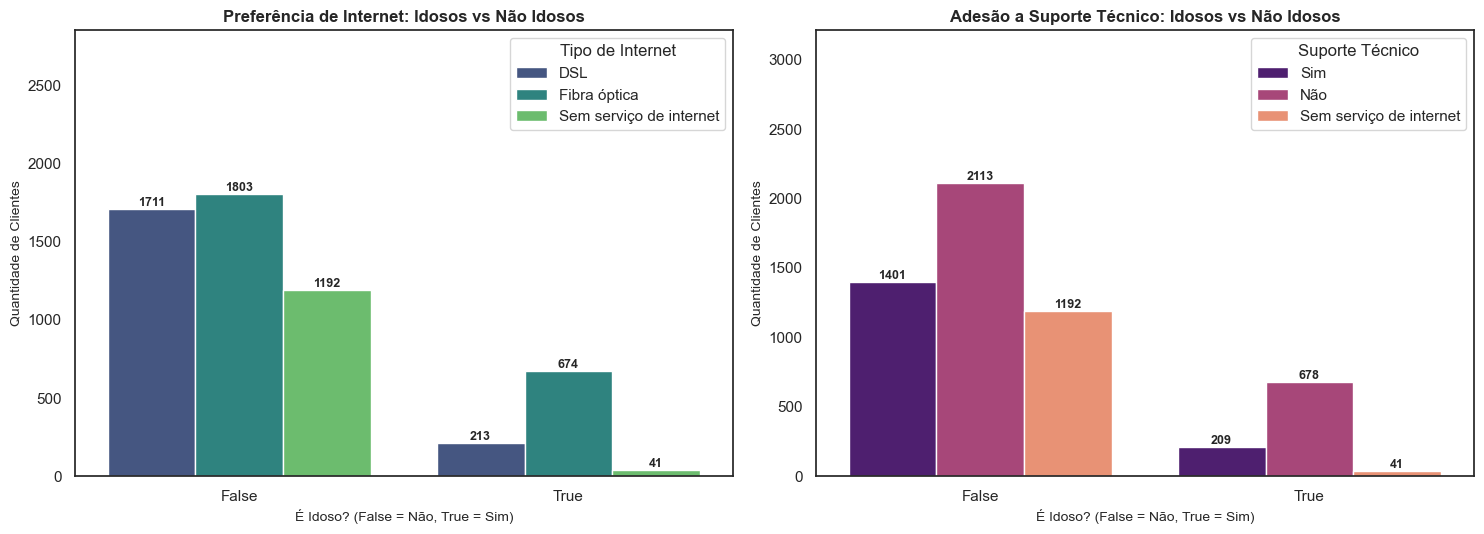

In [86]:
# Configurar o estilo visual sem grades
sns.set_theme(style='white')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# --- GRÁFICO 1: Preferência de Internet ---
ax1 = sns.countplot(
    data=df,
    x='Idoso',
    hue='Servico_Internet',
    palette='viridis',
    ax=axes[0],
)
axes[0].set_title(
    'Preferência de Internet: Idosos vs Não Idosos',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('É Idoso? (False = Não, True = Sim)', fontsize=10)
axes[0].set_ylabel('Quantidade de Clientes', fontsize=10)
axes[0].legend(title='Tipo de Internet')
axes[0].grid(False)

# Adicionar os valores em cima das barras do Gráfico 1
for p in ax1.patches:
  height = p.get_height()
  if height > 0:  # Só escreve se a barra tiver altura maior que zero
    ax1.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )
axes[0].set_ylim(0, df['Servico_Internet'].value_counts().max() * 1.15)


# --- GRÁFICO 2: Adesão a Suporte Técnico ---
ax2 = sns.countplot(
    data=df, x='Idoso', hue='Suporte_Tecnico', palette='magma', ax=axes[1]
)
axes[1].set_title(
    'Adesão a Suporte Técnico: Idosos vs Não Idosos',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('É Idoso? (False = Não, True = Sim)', fontsize=10)
axes[1].set_ylabel('Quantidade de Clientes', fontsize=10)
axes[1].legend(title='Suporte Técnico')
axes[1].grid(False)

# Adicionar os valores em cima das barras do Gráfico 2
for p in ax2.patches:
  height = p.get_height()
  if height > 0:
    ax2.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )
axes[1].set_ylim(0, df['Suporte_Tecnico'].value_counts().max() * 1.15)


plt.tight_layout()
plt.show()

### Conclusão - Análise do Público Idoso x Serviços
* **Forte adoção da Fibra Óptica:** 72,6% dos clientes idosos utilizam o serviço de Fibra Óptica, demonstrando alta migração para a tecnologia mais rápida em comparação aos clientes não idosos (38,3%).
* **Baixa contratação de Suporte Técnico:** Apesar de concentrarem o uso em conexões de alta velocidade, 73,1% dos idosos não possuem o plano de Suporte Técnico, o que representa um risco de experiência do usuário e uma oportunidade latente de campanhas de segurança e suporte voltadas para essa faixa etária.

____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

### **Ter cônjuge ou dependentes influencia na contratação de múltiplas linhas telefônicas (várias linhas) e serviços de entretenimento (Sreaming_TV e Streaming_Filmes)?**

In [87]:
# Visualizar o nome das colunas
print(df.columns)

Index(['ID_Cliente', 'Genero', 'Idoso', 'Conjuge', 'Dependentes',
       'Tempo_Assinatura', 'Servico_Telefonia', 'Varias_Linhas',
       'Servico_Internet', 'Seguranca_Online', 'Backup_Online',
       'Protecao_Dispositivos', 'Suporte_Tecnico', 'Streaming_TV',
       'Streaming_Filmes', 'Contrato', 'Faturamento_Eletronico',
       'Forma_Pagamento', 'Valores_Mensais', 'Valores_Totais',
       'Status_Cancelamento', 'Feedback_Cliente', 'Renda_Mensal'],
      dtype='object')


In [88]:
# 1. Tabela de contingência para Cônjuge vs Streaming de TV (em porcentagem)
crosstab_conjuge_tv = (
    pd.crosstab(df['Conjuge'], df['Streaming_TV'], normalize='index') * 100
)
print('--- Proporção de Streaming de TV por Cônjuge (%) ---')
print(crosstab_conjuge_tv)
print('\n' + '=' * 50 + '\n')

# 2. Tabela de contingência para Dependentes vs Múltiplas Linhas
crosstab_dep_linhas = (
    pd.crosstab(df['Dependentes'], df['Varias_Linhas'], normalize='index') * 100
)
print('--- Proporção de Várias Linhas por Dependentes (%) ---')
print(crosstab_dep_linhas)

--- Proporção de Streaming de TV por Cônjuge (%) ---
Streaming_TV        Não  Sem serviço de internet        Sim
Conjuge                                                    
False         45.717234                21.534228  32.748538
True          32.636597                22.258893  45.104510


--- Proporção de Várias Linhas por Dependentes (%) ---
Varias_Linhas        Não  Sem serviço de telefonia        Sim
Dependentes                                                  
False          47.176500                 10.078501  42.744999
True           49.910979                  9.792285  40.296736


Utilizamos o pd.crosstab com normalização por linha (normalize='index') para comparar diretamente o comportamento percentual entre quem tem e quem não tem cônjuge/dependentes.

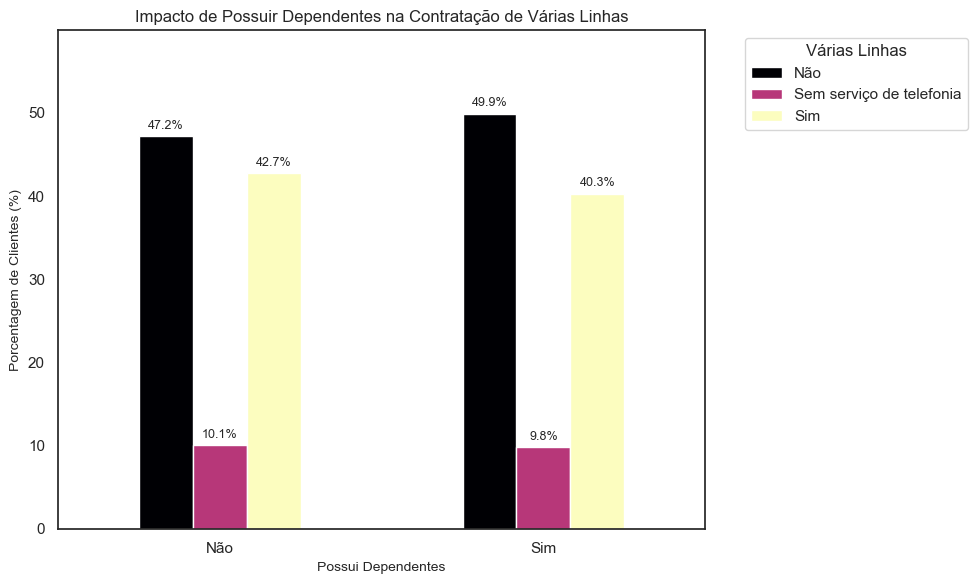

In [89]:
# 1. Gerando a tabela cruzada com porcentagens
tabela = (
    pd.crosstab(df['Dependentes'], df['Varias_Linhas'], normalize='index')
    * 100
)

# 2. Plotando o gráfico de barras agrupadas
ax = tabela.plot(kind='bar', stacked=False, figsize=(10, 6), colormap='magma')

# 3. Adicionando os valores em cima de cada barra
for p in ax.patches:
  height = p.get_height()
  if (
      height > 0
  ):  # Evita colocar rótulo em barras com altura zero (se houver)
    ax.annotate(
        f'{height:.1f}%',  # Formata o número com 1 casa decimal e o símbolo %
        (p.get_x() + p.get_width() / 2., height),  # Posição X e Y do texto
        ha='center',  # Alinhamento horizontal centralizado
        va='bottom',  # Alinhamento vertical logo acima da barra
        xytext=(0, 3),  # Deslocamento leve para cima em pixels
        textcoords='offset points',
        fontsize=9,
    )

# 4. Personalizações estéticas e limites do eixo Y
plt.title(
    'Impacto de Possuir Dependentes na Contratação de Várias Linhas', fontsize=12
)
plt.xlabel('Possui Dependentes', fontsize=10)
plt.ylabel('Porcentagem de Clientes (%)', fontsize=10)

# Ajustando o eixo X para 'Não' e 'Sim' em vez de False/True
plt.xticks([0, 1], ['Não', 'Sim'], rotation=0)

# Deixando um espaço extra no eixo Y para o texto não cortar no topo
plt.ylim(0, tabela.max().max() + 10)

# Posicionando a legenda fora do gráfico para ficar limpo
plt.legend(title='Várias Linhas', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### Conclusão

Comportamento dos ususários: Ao contrário do que o senso comum sugere, a proporção de clientes que contratam múltiplas linhas telefônicas permanece praticamente idêntica (~40%) tanto para clientes que possuem dependentes quanto para aqueles que não possuem.

Oportunidade de Portfólio: A ausência de diferença significativa indica que as ofertas atuais de linhas adicionais não estão sendo comercializadas como um "pacote familiar" efetivo.

Ação Recomendada: A empresa pode estruturar campanhas de marketing direcionadas (como planos família com descontos progressivos) para lares com dependentes, estimulando o crescimento desse indicador que hoje está estagnado.

____________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________


### **Existe diferença significativa na escolha dos serviços adicionais (Segurança Online, Backup, Proteção de Dispositivos) entre homens e mulheres (Genero)?**

Objetivo: Verificar se o gênero é um fator relevante na contratação de pacotes ou se o comportamento de consumo é equilibrado.

Análise de Serviços Adicionais por Gênero:

Investigamos se o perfil de gênero (Genero) influencia de forma estatisticamente relevante a contratação de camadas de proteção digital, como Seguranca_Online, Backup_Online e Protecao_Dispositivos. O objetivo é validar se estratégias de vendas futuras para esses complementos devem ser segmentadas por público ou mantidas padronizadas.

--- Proporção de Seguranca_Online por Gênero (%) ---
Seguranca_Online        Não  Sem serviço de internet        Sim
Genero                                                         
Feminino          49.124687                21.221865  29.653448
Masculino         50.370370                22.539683  27.089947


--- Proporção de Backup_Online por Gênero (%) ---
Backup_Online        Não  Sem serviço de internet        Sim
Genero                                                      
Feminino       43.301179                21.221865  35.476956
Masculino      43.915344                22.539683  33.544974


--- Proporção de Protecao_Dispositivos por Gênero (%) ---
Protecao_Dispositivos        Não  Sem serviço de internet        Sim
Genero                                                              
Feminino               43.944266                21.221865  34.833869
Masculino              43.703704                22.539683  33.756614




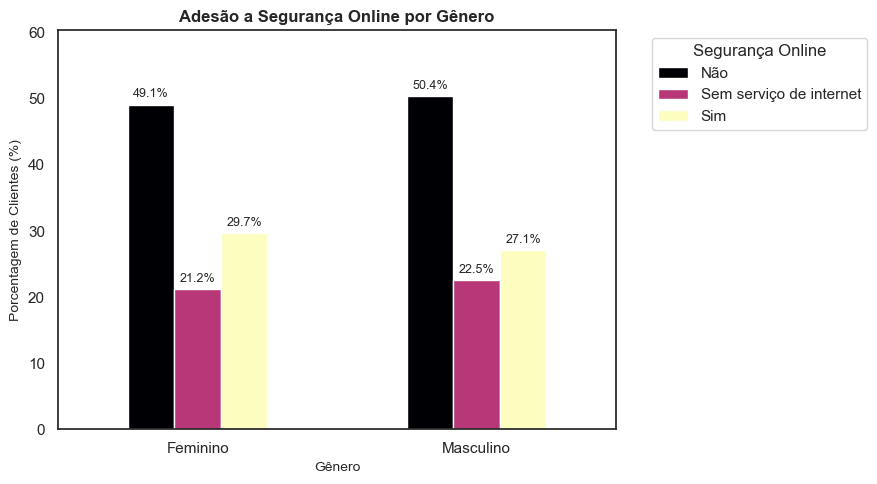

In [90]:
# 1. Lista com os serviços adicionais que queremos analisar
servicos_adicionais = [
    'Seguranca_Online',
    'Backup_Online',
    'Protecao_Dispositivos',
]

# 2. Loop para calcular e exibir as tabelas cruzadas em porcentagem para cada serviço
for servico in servicos_adicionais:
  print(f'--- Proporção de {servico} por Gênero (%) ---')
  tabela = (
      pd.crosstab(df['Genero'], df[servico], normalize='index') * 100
  )
  print(tabela)
  print('\n' + '=' * 50 + '\n')

# 3. Exemplo de Gráfico de Barras Agrupadas para 'Seguranca_Online' por Gênero
tabela_seg = (
    pd.crosstab(df['Genero'], df['Seguranca_Online'], normalize='index') * 100
)

ax = tabela_seg.plot(kind='bar', stacked=False, figsize=(9, 5), colormap='magma')

# Adicionando os valores em cima das barras
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:.1f}%',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points',
        fontsize=9,
    )

plt.title(
    'Adesão a Segurança Online por Gênero', fontsize=12, fontweight='bold'
)
plt.xlabel('Gênero', fontsize=10)
plt.ylabel('Porcentagem de Clientes (%)', fontsize=10)
plt.xticks(rotation=0)
plt.ylim(0, tabela_seg.max().max() + 10)
plt.legend(
    title='Segurança Online', bbox_to_anchor=(1.05, 1), loc='upper left'
)
plt.tight_layout()
plt.show()

### Conclusão:

Comportamento Equilibrado: Os dados demonstram que não há diferença significativa na contratação de serviços de segurança e backup entre homens e mulheres; as taxas de adoção e recusa seguem o mesmo padrão para ambos os gêneros.

Direcionamento de Marketing: Campanhas de cross-selling voltadas para cibersegurança e proteção de dados não precisam ser segmentadas por gênero, otimizando o custo de aquisição e o foco dos criativos.

Oportunidade Geral: Como a adesão a esses complementos costuma ser baixa no geral (muitos clientes ficam na categoria "Não"), o foco de negócio deve ser educar toda a base de clientes sobre a importância da segurança digital, independentemente do gênero.

__________________________________________________________________________________________________________________________________________

### **Qual perfil de cliente contrata a maior quantidade de serviços combinados (pacotes completos) vs. apenas serviços básicos?**

**Objetivo:** Desenvolver uma métrica sintética (`Total_Servicos`) que consolida todos os produtos contratados por cada cliente (telefonia, internet, streamings e complementos de segurança), mapeando o nível de engajamento da base.

**Como funciona a métrica:**
Na base de dados, os serviços vêm preenchidos como `"Sim"`, `"Não"` ou `"Sem serviço de internet"`. Para contabilizar o total de produtos por cliente, criamos uma lógica que converte cada resposta afirmativa (`"Sim"`) em **1** e os demais casos em **0**, somando todas as colunas de serviços ao final.

In [91]:
# 1. Lista de colunas que representam os serviços contratados no dataset
colunas_servicos = [
    'Servico_Telefonia',
    'Varias_Linhas',
    'Servico_Internet',
    'Seguranca_Online',
    'Backup_Online',
    'Protecao_Dispositivos',
    'Suporte_Tecnico',
    'Streaming_TV',
    'Streaming_Filmes',
]


# 2. Função para transformar respostas afirmativas em 1 e o restante em 0
def converter_para_binario(valor):
  if isinstance(valor, str) and valor.strip().lower() == 'sim':
    return 1
  return 0


# 3. Criando a nova métrica 'Total_Servicos' somando todas as colunas mapeadas
df['Total_Servicos'] = 0
for col in colunas_servicos:
  df['Total_Servicos'] += df[col].apply(converter_para_binario)

# 4. Exibindo as primeiras linhas para validar a nova métrica criada
print(
    df[['ID_Cliente', 'Total_Servicos', 'Conjuge', 'Dependentes', 'Idoso']]
    .head(10)
)

   ID_Cliente  Total_Servicos  Conjuge  Dependentes  Idoso
0  4578-PHJYZ               4     True         True  False
1  6289-CPNLD               4     True         True  False
2  2682-KEVRP               0    False        False   True
3  5697-GOMBF               1     True         True   True
4  9717-QEBGU               0    False        False  False
5  6797-LNAQX               4     True         True  False
6  3050-GBUSH               1    False        False  False
7  8020-BWHYL               1    False        False   True
8  6752-APNJL               2     True         True  False
9  1760-CAZHT               0    False         True  False


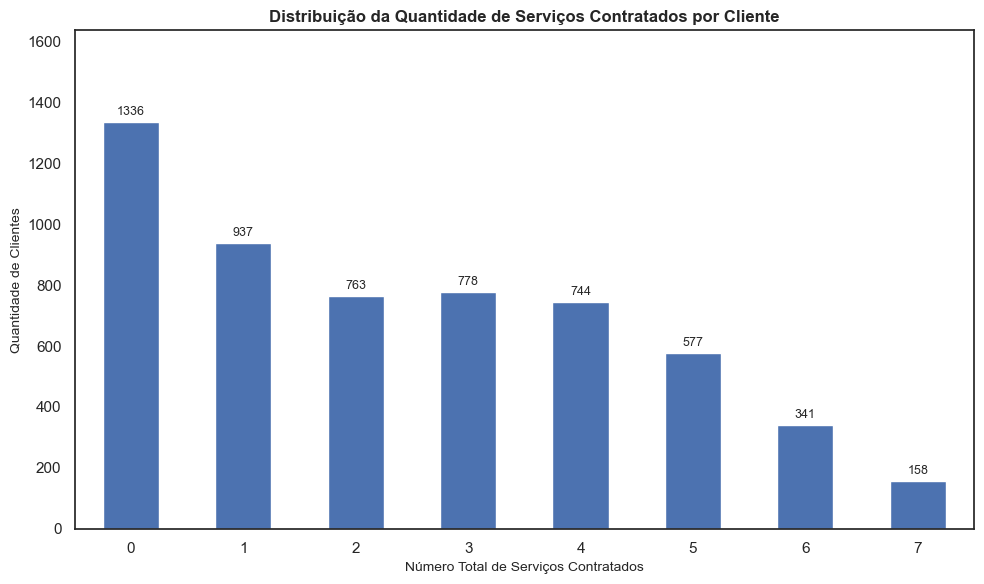

In [92]:
# 1. Calculando a contagem de clientes por quantidade total de serviços
contagem_servicos = df['Total_Servicos'].value_counts().sort_index()

# 2. Plotando o gráfico de barras
ax = contagem_servicos.plot(kind='bar', figsize=(10, 6), color='#4c72b0')

# 3. Adicionando os valores exatos em cima de cada barra
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points',
        fontsize=9,
    )

# 4. Personalizações estéticas do gráfico
plt.title(
    'Distribuição da Quantidade de Serviços Contratados por Cliente',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Número Total de Serviços Contratados', fontsize=10)
plt.ylabel('Quantidade de Clientes', fontsize=10)
plt.xticks(rotation=0)
plt.ylim(0, contagem_servicos.max() + 300)
plt.tight_layout()
plt.show()

### Conclusão:

Alta Concentração em Baixo Volume: O maior volume de clientes concentra-se em 0 ou 1 serviço adicional, indicando que a grande maioria da base ainda utiliza produtos de forma isolada e não possui pacotes integrados (bundles).

Oportunidade de Upsell e Cross-Sell: A curva estável entre 2 e 4 serviços mostra que existe um espaço saudável de adoção, mas campanhas de marketing direcionadas poderiam empurrar os clientes da faixa de 1 serviço para pacotes mais completos.

Efeito Fidelidade (Stickiness): Clientes que atingem um alto número de serviços (5 a 7) representam uma parcela menor, porém altamente valiosa e engajada, sendo os perfis com menor probabilidade de churn devido ao alto custo de substituição dos serviços combinados.